## Importación de librerías

In [61]:
import os
import re
import string

import pandas as pd
import numpy as np

import nltk
nltk.download('punkt_tab')
from nltk.stem import PorterStemmer
from nltk.tokenize import word_tokenize

import spacy
nlp = spacy.load("en_core_web_lg")
palabras_vacias = nlp.Defaults.stop_words

from sklearn.preprocessing import RobustScaler
from sklearn.model_selection import train_test_split

from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.cluster import KMeans

from scipy.optimize import linear_sum_assignment
from sklearn.metrics import confusion_matrix, precision_score, recall_score, f1_score, ConfusionMatrixDisplay

import matplotlib.pyplot as plt

[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\mansu\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


## Gold Standard

In [ ]:
RUTA_CORPUS = './Corpus-Clustering/'

gold_standard : dict[str, int] = {}
mapeado_etiquetas : dict[int, str] = {}

codificacion_etiqueta = 0

for etiqueta in os.listdir(RUTA_CORPUS):

	mapeado_etiquetas[codificacion_etiqueta] = etiqueta

	for documento in os.listdir(os.path.join(RUTA_CORPUS, etiqueta)):
		if documento in gold_standard:
			print('documento duplicado :', documento)
			continue
		
		gold_standard[documento] = codificacion_etiqueta

	codificacion_etiqueta += 1

## Preprocesado

In [ ]:
# Funciones de eliminación/sustitución de caracteres

def eliminar_cabecera(texto: list[str]) -> list[str]:
	"""
	Eliminación de la cabecera: todos los documentos tienen la cabecera
	en las n primeras líneas, aunque con n desconocido. Lo que sí se sabe
	es que todas las líneas de la cabecera van consecutivas y entre la 
	cabecera y el cuerpo del documento se pueden encontrar, al menos, una
	línea en blanco. Por ello, se buscará la aparición de la primera línea
	en blanco y se tomará el documento como que parte desde ahí.
	"""
	if len(texto) > 0:
		return texto[texto.index('\n')+1:]
	else:
		return []

def eliminar_firmas(texto: list[str]) -> list[str]:
	"""
	Eliminación de las firmas de los documentos: se puede observar que algunas
	de las firmas pueden aparecer explícitamente divididas del texto
	relevante del documento usando una fila de caracteres "-", "_", "=" o "+"
	seguidos de un posible espacio en blanco o los caracteres "\n" y/o "\r". 
	La firma debe ser el final del documento y, además, típicamente algo cortas. 
	Por ello se buscará la PRIMERA línea que cumpla la expresión regular: 
	^[ \t]*[-+=_]+[ \t\n\r]*$ y se comprobará si el número de líneas que le siguen a 
	partir de él no supera a las 10 líneas.

	Esta operación también puede provocar que se elimine texto que no se 
	considere una firma.
	"""
	if len(texto) == 0:
		return []

	for indice in range(0, len(texto)):
		if re.match('^[ \t]*[-+=_]+[ \t\n\r]*$', texto[indice]):
			break
	
	# También se comprueba que no sea la última posición
	if len(texto[indice:]) <= 10 and indice != len(texto)-1:
		texto_intermedio = texto[:indice]
	else:
		texto_intermedio = texto
	
	return texto_intermedio

def eliminar_lineas_blanco(texto: list[str]) -> list[str]:
	"""
	Eliminación de las líneas en blanco: todas las líneas que sean caracteres
	en blanco, como los espacios, los \n, tabuladores, etc. se eliminan, pues
	no aportan información.
	"""
	if len(texto) > 0:
		return [ linea for linea in texto if linea.strip() ]
	else:
		return []

def eliminar_multiples_carecteres_blanco(texto: str) -> str:
	"""
	"""
	if len(texto) > 0:
		return re.sub(r"\s+", ' ', texto)
	else:
		return ''

def eliminar_correos_electronicos(texto: str) -> str:
	"""
	Eliminación de los correos electrónicos.
	"""
	if len(texto) > 0:
		return re.sub(r'\w+(?:\.\w+)*@\w+(?:\.\w+)+', '', texto)
	else:
		return ''

def eliminar_signos_puntuacion(texto: str) -> str:
	if len(texto) > 0:
		return texto.translate(str.maketrans(dict.fromkeys(string.punctuation, ' ')))
	else:
		return ''

def eliminar_numeros(texto: str) -> str:
	"""
	Eliminación de todas las cadenas de texto que representen cantidades (puntos
	y comas incluídos)
	"""
	if len(texto) > 0:
		return re.sub(r'\d+(?:[\.,]\d+)?', '', texto)
	else:
		return ''

# ##############################################################################
# Funciones de eliminación/modificación de palabras

def eliminar_palabras_vacias(texto_original: list[str]) -> list[str]:
	"""
	Elimina las palabras vacías que se encuentren en el texto según el conjunto
	definido en `palabras_vacias`.
	"""
	return [palabra for palabra in texto_original if palabra not in palabras_vacias and len(palabra) != 1]

def stemmer(texto_original: str):
	"""
	Aplicación del stemmer de Porter sobre el texto.
	"""
	ps = PorterStemmer()
	texto_stemmer = word_tokenize(texto_original)

	texto_final = []

	for palabra in texto_stemmer:
		texto_final.append(ps.stem(palabra))

	return ' '.join(texto_final)

# ##############################################################################
# Otras

def tokenizado(texto: str) -> list[str]:
	"""
	División del texto por palabras.
	"""
	return re.split(' +', texto)

def calcular_frecuencia(texto: str):
	"""
	Calcula la frecuencia de cada palabra en el texto.
	"""
	frecuencia_rasgos: dict[str, int] = {}

	for rasgo in texto.split(' '):
		if rasgo not in frecuencia_rasgos:
			frecuencia_rasgos[rasgo] = 0
		frecuencia_rasgos[rasgo] += 1
	
	return frecuencia_rasgos

In [4]:
# Conteo de palabras
conteo_palabras: dict[str, list[int]] = {}

for documento, etiqueta in gold_standard.items():

	if etiqueta not in conteo_palabras:
		conteo_palabras[etiqueta] = []

	with open(os.path.join(RUTA_CORPUS, mapeado_etiquetas[etiqueta], documento), 'r') as fp:
		texto = fp.readlines()

	conteo_palabras[etiqueta].append(
		len(
			tokenizado(
				eliminar_multiples_carecteres_blanco(
					' '.join(eliminar_lineas_blanco(texto))
				)
			)
		)
	)

# Una vez terminado hay que recorrer cada clase para calcular la media y la 
# desviación
for clase, lista in conteo_palabras.items():
	print(f">> Clase {clase}:")
	print(f"Mínimo: {np.min(lista)}")
	print(f"Máximo: {np.max(lista)}")
	print(f"Media: {round(np.mean(lista), 2)}")
	print(f"Desviación típica: {round(np.std(lista), 2)}")

>> Clase 0:
Mínimo: 48
Máximo: 4159
Media: 248.7
Desviación típica: 373.05
>> Clase 1:
Mínimo: 29
Máximo: 723
Media: 185.38
Desviación típica: 108.42
>> Clase 2:
Mínimo: 31
Máximo: 853
Media: 217.21
Desviación típica: 170.52
>> Clase 3:
Mínimo: 33
Máximo: 1570
Media: 274.88
Desviación típica: 265.68
>> Clase 4:
Mínimo: 48
Máximo: 11840
Media: 266.78
Desviación típica: 807.43
>> Clase 5:
Mínimo: 68
Máximo: 3869
Media: 415.33
Desviación típica: 473.05
>> Clase 6:
Mínimo: 55
Máximo: 10385
Media: 727.88
Desviación típica: 1321.51


In [ ]:
# Aplicación del preprocesado
RUTA_CORPUS_LIMPIO = './corpus-clustering-limpio/'

if not os.path.exists(RUTA_CORPUS_LIMPIO):
	os.mkdir(RUTA_CORPUS_LIMPIO)

frecuencia_rasgo_en_documento: dict[str, dict[str, int]] = {}

for documento, etiqueta in gold_standard.items():

	with open(os.path.join(RUTA_CORPUS, mapeado_etiquetas[etiqueta], documento), 'r') as fp:
		texto = fp.readlines() 

	# Eliminación de secciones
	texto_intermedio = eliminar_cabecera(texto)
	texto_intermedio = eliminar_firmas(texto_intermedio)
	texto_intermedio = eliminar_lineas_blanco(texto_intermedio)

	# Unión del texto en una sola línea
	texto_intermedio = ' '.join(texto_intermedio)

	# Eliminación de caracteres
	texto_intermedio = eliminar_multiples_carecteres_blanco(texto_intermedio)
	texto_intermedio = eliminar_correos_electronicos(texto_intermedio)
	texto_intermedio = eliminar_signos_puntuacion(texto_intermedio)
	texto_intermedio = eliminar_numeros(texto_intermedio)
	
	# Modificación de caracteres
	texto_intermedio = texto_intermedio.lower()

	texto_tokenizado = tokenizado(texto_intermedio)

	texto_limpio = ' '.join(eliminar_palabras_vacias(texto_tokenizado))

	# Almacenamiento de los textos limpios
	if not os.path.exists(os.path.join(RUTA_CORPUS_LIMPIO, mapeado_etiquetas[etiqueta])):
		os.mkdir(os.path.join(RUTA_CORPUS_LIMPIO, mapeado_etiquetas[etiqueta]))

	with open(os.path.join(RUTA_CORPUS_LIMPIO, mapeado_etiquetas[etiqueta], documento), 'w') as fp:
		fp.write(texto_limpio)

	# Extracción de las raices
	texto_stemmer = stemmer(texto_limpio)
		
	frecuencia_rasgo_en_documento[documento] = calcular_frecuencia(texto_stemmer)

## Funciones de pesado

In [ ]:
aparicion_rasgos_en_documentos: dict[str, set] = {}

# Cálculo del DF
for documento, rasgos in frecuencia_rasgo_en_documento.items():
	for rasgo in rasgos.keys():
		if rasgo not in aparicion_rasgos_en_documentos:
			aparicion_rasgos_en_documentos[rasgo] = set()
		aparicion_rasgos_en_documentos[rasgo].add(documento)

# Eliminación de los rasgos que aparezcan en muy pocos documentos (mínimo 6) y
# de los rasgos que sean solo una letra
aparicion_rasgos_en_documentos_frecuentes : dict[str, set] = {}
for rasgo, conjunto in aparicion_rasgos_en_documentos.items():
	if len(conjunto) >= 7:
		aparicion_rasgos_en_documentos_frecuentes[rasgo] = conjunto

# Información relevante a mano
numero_documentos = len(gold_standard.keys())

rasgos = list(aparicion_rasgos_en_documentos_frecuentes.keys())
documentos = list(gold_standard.keys())

### Normalización logarítmica

In [ ]:
matriz_norm_log = pd.DataFrame(data=[], index=rasgos, columns=documentos)

for documento, lista_rasgos in frecuencia_rasgo_en_documento.items():
	matriz_norm_log[documento] = matriz_norm_log[documento].astype(np.float64)
	# No aseguramos que solo los rasgos para los que existe índice sean añadidos
	matriz_norm_log[documento] = np.log(pd.Series(lista_rasgos) + 1)

matriz_norm_log = matriz_norm_log.fillna(0)

matriz_norm_log = matriz_norm_log.T

matriz_norm_log.to_csv('./matriz_norm_log.csv',sep=";", index=True, header=True)

In [7]:
matriz_norm_log = pd.read_csv('./matriz_norm_log.csv', sep=';', index_col=0, header=0)
matriz_norm_log.index = matriz_norm_log.index.astype('str')

In [76]:
(matriz_norm_log == 0).astype(int).sum().sum()

np.int64(1489060)

### TF-IDF

In [ ]:
# El TF ya se encuentra en el diccionario frecuencia_rasgo_en_documento

# IDF 
# Filas: rasgos. Columnas: documentos.
matriz_tf_idf = pd.DataFrame(data=[], index=rasgos, columns=documentos)

# Añadido de la frecuencia
for documento, lista_rasgos in frecuencia_rasgo_en_documento.items():
	matriz_tf_idf[documento] = matriz_tf_idf[documento].astype(np.float64)
	matriz_tf_idf[documento] = pd.Series(lista_rasgos)

# Los campos con NaN se ponen a 0
matriz_tf_idf = matriz_tf_idf.infer_objects().fillna(0.0)

# Añadido del IDF. Constante para cada rasgo
for rasgo in matriz_tf_idf.index:
	matriz_tf_idf.loc[rasgo] *= np.log(
		numero_documentos / (1 + len(aparicion_rasgos_en_documentos[rasgo]))
	)

matriz_tf_idf = matriz_tf_idf.T

matriz_tf_idf.to_csv('./matriz_tf_idf.csv', sep=";", index=True, header=True)

matriz_tf_idf

In [8]:
matriz_tf_idf = pd.read_csv('./matriz_tf_idf.csv', sep=';', index_col=0)
matriz_tf_idf.index = matriz_tf_idf.index.astype('str')

## Clustering

In [ ]:
# División de datos
documentos = list(gold_standard.keys())
etiquetado = list(gold_standard.values())

doc_train, doc_test, etq_train, etq_test = train_test_split(
	documentos, etiquetado, test_size=0.3, random_state=0
)

matriz_norm_log_train = matriz_norm_log.loc[doc_train]
matriz_norm_log_test = matriz_norm_log.loc[doc_test]

matriz_tf_idf_train = matriz_tf_idf.loc[doc_train]
matriz_tf_idf_test = matriz_tf_idf.loc[doc_test]

metricas = {
	'kmeans' : {
		'log' : {},
		'tf_idf' : {}
	},
	'lda' : {
		'log' : {},
		'tf_idf' : {}
	}
}

In [23]:
# Escalado
escalador_norm_log = RobustScaler()

matriz_norm_log_train_escalado = escalador_norm_log.fit_transform(matriz_norm_log_train)
matriz_norm_log_test_escalado = escalador_norm_log.transform(matriz_norm_log_test)

escalador_tf_idf = RobustScaler()

matriz_tf_idf_train_escalado = escalador_tf_idf.fit_transform(matriz_tf_idf_train)
matriz_tf_idf_test_escalado = escalador_tf_idf.transform(matriz_tf_idf_test)

#### Algoritmo K-means

In [25]:
kmeans = KMeans(n_clusters=7, random_state=0, n_init=50)

{'precision': 0.2253375763309538, 'recall': 0.18949579831932775, 'f1': 0.14304112934249918}


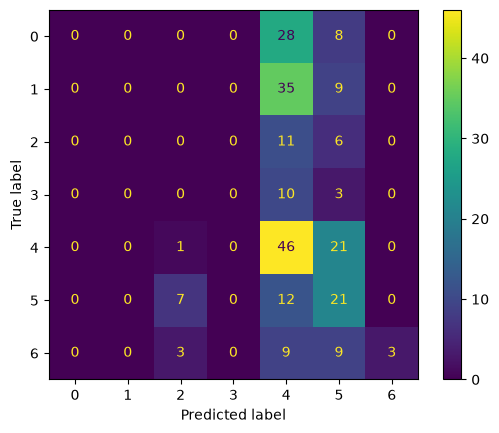

In [65]:
# Normalización logarítmica
kmeans.fit(matriz_norm_log_train_escalado)
prediccion_kmeans_norm_log_test = kmeans.predict(matriz_norm_log_test_escalado)

# Mapeado de las clases
filas, cols = linear_sum_assignment(
	-confusion_matrix(np.array(etq_test), prediccion_kmeans_norm_log_test)
)

mapeado_predicho_real = dict(zip(cols, filas))

# Sustituir las predicciones con la etiqueta real:
prediccion_kmeans_norm_log_test_mapeado = np.array([mapeado_predicho_real[etiqueta] for etiqueta in prediccion_kmeans_norm_log_test])

metricas['kmeans']['log'] = {
	'precision' : precision_score(etq_test, prediccion_kmeans_norm_log_test_mapeado, average='macro', zero_division=0),
	'recall' : recall_score(etq_test, prediccion_kmeans_norm_log_test_mapeado, average='macro', zero_division=0),
	'f1' : f1_score(etq_test, prediccion_kmeans_norm_log_test_mapeado, average='macro', zero_division=0)
}

print(metricas['kmeans']['log'])

ConfusionMatrixDisplay(confusion_matrix(np.array(etq_test), prediccion_kmeans_norm_log_test_mapeado)).plot()
plt.show()

{'precision': 0.04014167650531287, 'recall': 0.14285714285714285, 'f1': 0.06267281105990784}


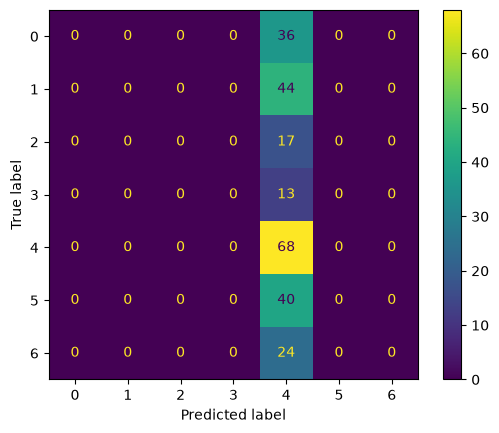

In [66]:
# TF-IDF
kmeans.fit(matriz_tf_idf_train_escalado)
prediccion_kmeans_tf_idf_test = kmeans.predict(matriz_tf_idf_test_escalado)

# Mapeado de las clases
filas, cols = linear_sum_assignment(
	-confusion_matrix(np.array(etq_test), prediccion_kmeans_tf_idf_test)
)

mapeado_predicho_real = dict(zip(cols, filas))

# Sustituir las predicciones con la etiqueta real:
prediccion_kmeans_tf_idf_test_mapeado = np.array([mapeado_predicho_real[etiqueta] for etiqueta in prediccion_kmeans_tf_idf_test])

metricas['kmeans']['tf_idf'] = {
	'precision' : precision_score(etq_test, prediccion_kmeans_tf_idf_test_mapeado, average='macro', zero_division=0),
	'recall' : recall_score(etq_test, prediccion_kmeans_tf_idf_test_mapeado, average='macro', zero_division=0),
	'f1' : f1_score(etq_test, prediccion_kmeans_tf_idf_test_mapeado, average='macro', zero_division=0)
}

print(metricas['kmeans']['tf_idf'])

ConfusionMatrixDisplay(confusion_matrix(np.array(etq_test), prediccion_kmeans_tf_idf_test_mapeado)).plot()
plt.show()

### LDA

In [28]:
lda = LinearDiscriminantAnalysis()

{'precision': 0.5152442002442003, 'recall': 0.4942222809869868, 'f1': 0.5024889030006813}


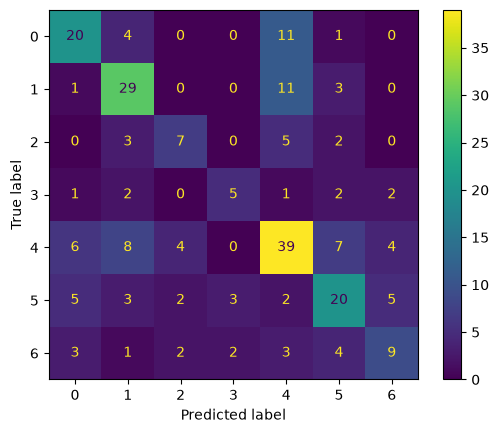

In [67]:
# Normalización logarítmica
lda.fit(matriz_norm_log_train_escalado, etq_train)
prediccion_lda_norm_log_test = lda.predict(matriz_norm_log_test_escalado)

metricas['lda']['log'] = {
	'precision' : precision_score(etq_test, prediccion_lda_norm_log_test, average='macro', zero_division=0),
	'recall' : recall_score(etq_test, prediccion_lda_norm_log_test, average='macro', zero_division=0),
	'f1' : f1_score(etq_test, prediccion_lda_norm_log_test, average='macro', zero_division=0)
}

print(metricas['lda']['log'])

ConfusionMatrixDisplay(confusion_matrix(np.array(etq_test), prediccion_lda_norm_log_test)).plot()
plt.show()

{'precision': 0.4616960082567777, 'recall': 0.4213125110183934, 'f1': 0.4355263186825726}


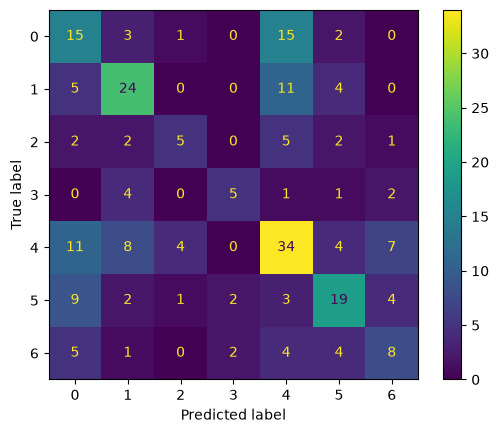

In [68]:
# TF-IDF
lda.fit(matriz_tf_idf_train_escalado, etq_train)
prediccion_lda_tf_idf_test = lda.predict(matriz_tf_idf_test_escalado)

metricas['lda']['tf_idf'] = {
	'precision' : precision_score(etq_test, prediccion_lda_tf_idf_test, average='macro', zero_division=0),
	'recall' : recall_score(etq_test, prediccion_lda_tf_idf_test, average='macro', zero_division=0),
	'f1' : f1_score(etq_test, prediccion_lda_tf_idf_test, average='macro', zero_division=0)
}

print(metricas['lda']['tf_idf'])

ConfusionMatrixDisplay(confusion_matrix(np.array(etq_test), prediccion_lda_tf_idf_test)).plot()
plt.show()